# 03 · Metrics and analysis
**Project:** Sales Variance FP&A Dashboard

The full analysis is done by `scripts/sales_variance_analysis.py`, which writes `data/processed/Sales_Variance_Enriched_Data.csv` and the Excel workbook `outputs/Sales_Variance_Analysis.xlsx`.
This notebook **reads those outputs**, recomputes the headline numbers independently in pandas, and checks that they agree.

In [1]:
from pathlib import Path
import warnings
import pandas as pd

warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40

# Works whether Jupyter starts in notebooks/ or in the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "sales_raw_messy_csv.xlsx"
CLEAN = ROOT / "data" / "processed" / "Cleaned_Sales_Data.csv"
ENRICHED = ROOT / "data" / "processed" / "Sales_Variance_Enriched_Data.csv"
WORKBOOK = ROOT / "outputs" / "Sales_Variance_Analysis.xlsx"

## 1. Headline numbers (recomputed from the line data)

In [2]:
df = pd.read_csv(ENRICHED, keep_default_na=False, na_values=[""], encoding="utf-8-sig")
target = df["Target_Sales_USD"].sum()
actual = df["Actual_Sales_USD"].sum()
variance = actual - target
print(f"Lines            : {len(df):,}")
print(f"Target sales     : ${target:,.2f}")
print(f"Actual sales     : ${actual:,.2f}")
print(f"Sales variance   : ${variance:,.2f}  ({variance / target * 100:+.2f}%)")
print(f"Qty attainment   : {df['Actual_Qty'].sum() / df['Target_Qty'].sum() * 100:.2f}%")
print(f"Price effect     : ${df['Price_Effect_USD'].sum():,.2f}")
print(f"Volume effect    : ${df['Volume_Effect_USD'].sum():,.2f}")

Lines            : 25,920
Target sales     : $488,211,924.15
Actual sales     : $478,746,895.61
Sales variance   : $-9,465,028.54  (-1.94%)
Qty attainment   : 98.03%
Price effect     : $0.00
Volume effect    : $-9,465,028.54


## 2. Variance by region and category
Percentages are `sum(variance) / sum(target)` — never an average of row percentages.

In [3]:
def by(col):
    g = df.groupby(col).agg(Target=("Target_Sales_USD", "sum"), Actual=("Actual_Sales_USD", "sum"))
    g["Variance_USD"] = g["Actual"] - g["Target"]
    g["Variance_Pct"] = g["Variance_USD"] / g["Target"] * 100
    return g.sort_values("Variance_USD")

region = by("Region")
region

,Target,Actual,Variance_USD,Variance_Pct
Region,,,,
Latin America,"96,689,061.90","89,666,270.53","-7,022,791.37",-7.26
Middle East,"97,124,212.83","94,744,448.02","-2,379,764.81",-2.45
North America,"97,618,771.28","95,276,635.33","-2,342,135.95",-2.40
Europe,"98,856,781.57","96,657,717.21","-2,199,064.36",-2.22
Asia Pacific,"97,923,096.57","102,401,824.52","4,478,727.95",4.57


In [4]:
by("Category")

,Target,Actual,Variance_USD,Variance_Pct
Category,,,,
Home Appliances,"108,744,484.10","105,873,567.66","-2,870,916.44",-2.64
Personal Care,"91,115,690.87","88,415,006.14","-2,700,684.73",-2.96
Sports Equipment,"90,940,618.12","88,414,350.00","-2,526,268.12",-2.78
Office Supplies,"89,502,741.80","87,174,736.34","-2,328,005.46",-2.60
Electronics,"107,908,389.26","108,869,235.47","960,846.21",0.89


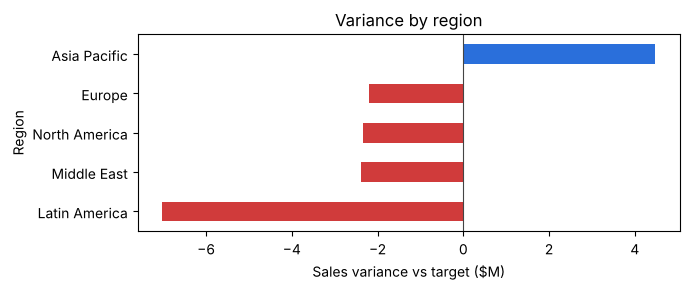

In [5]:
import matplotlib.pyplot as plt
ax = region["Variance_USD"].div(1e6).plot.barh(color=["#d03b3b" if v < 0 else "#2a6fdb" for v in region["Variance_USD"]], figsize=(7, 3))
ax.set_xlabel("Sales variance vs target ($M)")
ax.set_title("Variance by region")
ax.axvline(0, color="#444", lw=0.8)
plt.tight_layout()
plt.show()

## 3. Months below target

In [6]:
monthly = df.assign(Year_Month=df["Year_Month"].astype(str)).groupby("Year_Month").agg(
    Target=("Target_Sales_USD", "sum"), Actual=("Actual_Sales_USD", "sum"))
monthly["Variance_USD"] = monthly["Actual"] - monthly["Target"]
print(f"Months below target: {(monthly['Variance_USD'] < 0).sum()} of {len(monthly)}")

Months below target: 24 of 24


## 4. Agreement with the Excel workbook

In [7]:
wb_region = pd.read_excel(WORKBOOK, sheet_name="By_Region").set_index("Region")
diff = (region["Variance_USD"] - wb_region["Sales_Variance_USD"]).abs().max()
print(f"Largest difference between pandas and the workbook (by region): ${diff:,.4f}")
assert diff < 0.01, "pandas and the workbook disagree"
print("OK - the notebook agrees with the workbook.")

Largest difference between pandas and the workbook (by region): $0.0000
OK - the notebook agrees with the workbook.


In [8]:
pd.read_excel(WORKBOOK, sheet_name="Executive_Summary")

,Item,Value,Comment
0,Rows analysed,"25,920",NaN
1,Period,2024-01 to 2025-12,24 months
2,Target sales (USD),"488,211,924.15",NaN
3,Actual sales (USD),"478,746,895.61",NaN
4,Total variance (USD),"-9,465,028.54",-1.94 %
5,Quantity attainment %,98.03,NaN
6,Rows Favorable / Unfavorable / On Target,"9,497 / 12,316 / 4,107",No Target: 0
7,Rows flagged Material,12968,50.0 % of rows
8,Volume effect (USD),"-9,465,028.54",NaN
9,Price effect (USD),0,NaN


## 5. Next steps
* Interactive dashboard: `dashboard/Sales_Variance_Dashboard.html` (open it in any browser).
* Written findings and recommendations: `docs/Insights_and_Recommendations.md`.